# Phase 2 — the strongest non-agent retriever

**Phase 2a — classic retrieval.** Every candidate was preregistered (`PREREGISTRATION.md`
§2, with amendment A2) before any result existed. All selection is on `tune` (500
validation questions), retrieval only, by overall exact-variant **Joint Recall@10**: the
share of questions with both gold paragraphs in the top 10.

The nine configurations:

- **C0:** the Phase 1 BM25.
- **C1:** C0 with normalized text.
- **C2:** C1 with the title repeated in the index text.
- **C3a, C3b:** BM25-weighted RM3-style feedback.
- **C4@5, C4@10:** forward title-mention graph expansion, from 5 or 10 seeds.
- **C5@5, C5@10:** bidirectional title-mention graph expansion, from 5 or 10 seeds.

This notebook only reads results written by `run_eval.py phase2a`. The blind test splits
are not loaded.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import graph
import hops
import metrics

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})


def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]


tune = data.load_split("tune")
qd = {q.qid: q for q in tune}
ctx = data.load_contexts("tune")
ids = data.doc_id_of()
corpus = data.corpus()
rows = {r["qid"]: r for r in read_jsonl("results/tune/phase2a_rankings.jsonl")}
sel = json.load(open("results/tune/phase2a_selection.json"))
man = json.load(open("results/tune/phase2a_rankings.jsonl.manifest.json"))
CONFIGS = ["C0", "C1", "C2", "C3a", "C3b", "C4@5", "C4@10", "C5@5", "C5@10"]
print(f"tune questions: {len(rows)}; configurations: {len(CONFIGS)}; B = {sel['B']}; C = {sel['C']}")
print("graph:", man["system_config"]["graph"]["version"], man["system_config"]["graph"]["fingerprint"][:16])

tune questions: 500; configurations: 9; B = C0; C = C5@5
graph: graph_v1+A2 c0a4b543a343a2bc


## 1. Selection (`tune`, n = 500)

The selection runs in two preregistered steps. Step 1 picks the lexical base B from
C0 → C1 → C2. Step 2 picks the classic champion C from B → C4@5 → C4@10 → C5@5 → C5@10 →
C3a → C3b. In both steps the rule is the first candidate in preference order within 0.02
of the best. Differences against C0 are paired bootstrap estimates with 95% intervals.

In [2]:
gold = {q.qid: [ids[g] for g in q.gold] for q in tune}
jr10 = {c: {qid: metrics.joint_recall(rows[qid]["rankings"][c][:10], gold[qid]) for qid in rows} for c in CONFIGS}

table = []
for c in CONFIGS:
    d = metrics.paired_bootstrap(jr10[c], jr10["C0"]) if c != "C0" else None
    table.append({"config": c,
                  "Joint Recall@10": np.mean(list(jr10[c].values())),
                  "bridge (400)": np.mean([jr10[c][q] for q in rows if qd[q].type == "bridge"]),
                  "comparison (100)": np.mean([jr10[c][q] for q in rows if qd[q].type == "comparison"]),
                  "vs C0": "" if d is None else f"{d['delta']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]"})
t = pd.DataFrame(table).set_index("config")
display(t.round(3))
print("step 1:", sel["step1"]["plateau"], "->", sel["B"], "| step 2:", sel["step2"]["plateau"], "->", sel["C"])
print(f"configurations evaluated: {sel['configurations_evaluated']} in 6 families")

,Joint Recall@10,bridge (400),comparison (100),vs C0
config,,,,
C0,0.608,0.550,0.84,
C1,0.608,0.550,0.84,"+0.000 [+0.000, +0.000]"
C2,0.626,0.562,0.88,"+0.018 [+0.002, +0.034]"
C3a,0.530,0.515,0.59,"-0.078 [-0.114, -0.042]"
C3b,0.566,0.545,0.65,"-0.042 [-0.074, -0.010]"
C4@5,0.774,0.772,0.78,"+0.166 [+0.124, +0.210]"
C4@10,0.762,0.765,0.75,"+0.154 [+0.110, +0.200]"
C5@5,0.796,0.812,0.73,"+0.188 [+0.144, +0.234]"
C5@10,0.792,0.810,0.72,"+0.184 [+0.138, +0.230]"


step 1: ['C0', 'C1', 'C2'] -> C0 | step 2: ['C5@5', 'C5@10'] -> C5@5
configurations evaluated: 9 in 6 families


C1's change of exactly +0.000 needs checking: was normalization actually applied? The
next cell compares C1 with C0 directly.

In [3]:
from normalize import norm_v1

diff10 = sum(rows[q]["rankings"]["C1"][:10] != rows[q]["rankings"]["C0"][:10] for q in rows)
setdiff10 = sum(set(rows[q]["rankings"]["C1"][:10]) != set(rows[q]["rankings"]["C0"][:10]) for q in rows)
diff100 = sum(rows[q]["rankings"]["C1"] != rows[q]["rankings"]["C0"] for q in rows)
print(f"questions changed by norm_v1: {sum(norm_v1(qd[q].question) != qd[q].question for q in rows)} / 500; "
      f"index texts changed: {sum(norm_v1(d.index_text) != d.index_text for d in corpus.values()):,} / {len(corpus):,}")
print(f"C1 vs C0 rankings: depth-100 differs {diff100}; top-10 order differs {diff10}; top-10 set differs {setdiff10}; "
      f"Joint Recall@10 changes {sum(jr10['C1'][q] != jr10['C0'][q] for q in rows)}")

questions changed by norm_v1: 107 / 500; index texts changed: 41,785 / 66,635
C1 vs C0 rankings: depth-100 differs 500; top-10 order differs 109; top-10 set differs 34; Joint Recall@10 changes 0


Normalization was applied: most index texts and a fifth of the questions changed, and
every depth-100 ranking differs. The top-10 set changed for 34 questions, but in none of
them did it change whether both gold paragraphs were in the top 10. The zero is a real
null result, as H2a-7 predicted, not an implementation error.

## 2. Where the gain comes from: hop-level diagnostics

Bridge questions with a determined hop order (Phase 0 rule, undetermined excluded and
counted): hop-1 and hop-2 Recall@10, and first-hop recall split by whether the question
names the first-hop title. Title-only Joint Recall is the secondary compatibility metric.

In [4]:
chains = {q.qid: hops.chain(q, ctx[q.qid]) for q in tune}
bridge = [q for q in tune if q.type == "bridge" and chains[q.qid].determined]
undetermined = sum(1 for q in tune if q.type == "bridge" and not chains[q.qid].determined)
hop_id = {q.qid: (ids[(chains[q.qid].first, dict(q.gold)[chains[q.qid].first])],
                  ids[(chains[q.qid].second, dict(q.gold)[chains[q.qid].second])]) for q in bridge}
named = {q.qid: hops.mentions(q.question, chains[q.qid].first) for q in bridge}
title_of = {d: corpus[d].title for d in corpus}


def hop_recall(c, qs, which):
    return float(np.mean([hop_id[q.qid][which] in rows[q.qid]["rankings"][c][:10] for q in qs]))


diag = []
for c in CONFIGS:
    top = {q: rows[q]["rankings"][c][:10] for q in rows}
    diag.append({"config": c,
                 "hop-1 R@10": hop_recall(c, bridge, 0), "hop-2 R@10": hop_recall(c, bridge, 1),
                 "hop-1 named": hop_recall(c, [q for q in bridge if named[q.qid]], 0),
                 "hop-1 unnamed": hop_recall(c, [q for q in bridge if not named[q.qid]], 0),
                 "JR@10 title-only": np.mean([metrics.joint_recall({title_of[d] for d in top[q]},
                                                                   [t for t, _ in qd[q].gold]) for q in rows])})
display(pd.DataFrame(diag).set_index("config").round(3))
print(f"bridge questions: 400 nominal, {len(bridge)} with determined hop order, {undetermined} undetermined; "
      f"first hop named in the question: {sum(named.values())}, unnamed: {len(bridge) - sum(named.values())}")

,hop-1 R@10,hop-2 R@10,hop-1 named,hop-1 unnamed,JR@10 title-only
config,,,,,
C0,0.903,0.620,0.942,0.828,0.608
C1,0.906,0.620,0.942,0.836,0.608
C2,0.926,0.620,0.969,0.843,0.626
C3a,0.852,0.602,0.888,0.784,0.530
C3b,0.865,0.625,0.891,0.813,0.566
C4@5,0.880,0.857,0.938,0.769,0.774
C4@10,0.867,0.862,0.922,0.761,0.762
C5@5,0.916,0.855,0.946,0.858,0.796
C5@10,0.913,0.855,0.946,0.851,0.792


bridge questions: 400 nominal, 392 with determined hop order, 8 undetermined; first hop named in the question: 258, unnamed: 134


## 3. Graph diagnostics

- **Coverage:** for how many bridge questions the graph even contains the needed edge,
  forward (hop 1 → hop 2) or backward (hop 2 → hop 1).
- **Additions:** gold paragraphs added by expansion.
- **Displacements:** gold paragraphs pushed out of B's top 10 by the reserved slots.
- **Noise:** the share of added paragraphs that are gold, micro-averaged over additions,
  by direction and by the in-degree of the contributing seed.

In [5]:
g = graph.load_or_build()
assert g.fingerprint() == man["system_config"]["graph"]["fingerprint"]
print("graph:", {k: v for k, v in g.stats.items() if k != "build_s"}, f"build {g.stats['build_s']:.0f} s")
fwd_cov = np.mean([hop_id[q.qid][1] in {d for _, _, d in g.targets(hop_id[q.qid][0])} for q in bridge])
bwd_cov = np.mean([hop_id[q.qid][0] in {d for _, _, d in g.targets(hop_id[q.qid][1])} for q in bridge])
print(f"\ncoverage over {len(bridge)} bridge questions: forward edge hop1->hop2 {fwd_cov:.3f}; backward edge hop2->hop1 {bwd_cov:.3f}; "
      f"either {np.mean([(hop_id[q.qid][1] in {d for _, _, d in g.targets(hop_id[q.qid][0])}) or (hop_id[q.qid][0] in {d for _, _, d in g.targets(hop_id[q.qid][1])}) for q in bridge]):.3f}")

B = sel["B"]
eff = []
for c in ("C4@5", "C4@10", "C5@5", "C5@10"):
    added_gold = displaced_gold = n_added = 0
    by = {("forward", "low"): [0, 0], ("forward", "high"): [0, 0], ("backward", "low"): [0, 0], ("backward", "high"): [0, 0]}
    for q in rows:
        adds = rows[q]["added"][c]
        n_added += len(adds)
        gset = set(gold[q])
        for a in adds:
            cls = (a["direction"], "high" if a["seed_in_degree"] >= 100 else "low")
            by[cls][0] += a["doc"] in gset
            by[cls][1] += 1
        added_gold += sum(a["doc"] in gset for a in adds)
        displaced_gold += len((set(rows[q]["rankings"][B][:10]) - set(rows[q]["rankings"][c][:10])) & gset)
    eff.append({"config": c, "added per query": n_added / 500, "gold added": added_gold, "gold displaced": displaced_gold,
                "net gold": added_gold - displaced_gold,
                **{f"{d} {h}-degree gold/added": f"{v[0]}/{v[1]}" + (f" = {v[0] / v[1]:.3f}" if v[1] else "")
                   for (d, h), v in by.items()}})
with pd.option_context("display.max_colwidth", 30, "display.width", 250):
    display(pd.DataFrame(eff).set_index("config"))
indeg = sorted((len(v) for v in g.incoming.values()), reverse=True)
print(f"in-degree: max {indeg[0]}, titles with in-degree >= 100: {sum(d >= 100 for d in indeg)}, median over linked titles {int(np.median(indeg))}")

graph: {'titles': 66581, 'aliases_permitted': 73295, 'aliases_rejected': {'frequent_single_token': 625, 'short': 265, 'digits': 22, 'stopwords_only': 6, 'ambiguous': 1255, 'frequent_alias_A2': 93, 'frequent_alias_A2_multi_token': 93}, 'edges': 98027, 'docs_with_out_edges': 48778, 'titles_with_in_edges': 18565, 'max_in_degree': 98, 'max_out_degree': 22} build 21 s

coverage over 392 bridge questions: forward edge hop1->hop2 0.816; backward edge hop2->hop1 0.046; either 0.819


,added per query,gold added,gold displaced,net gold,forward low-degree gold/added,forward high-degree gold/added,backward low-degree gold/added,backward high-degree gold/added
config,,,,,,,,
C4@5,3.798,145,31,114,145/1899 = 0.076,0/0,0/0,0/0
C4@10,4.798,152,42,110,152/2399 = 0.063,0/0,0/0,0/0
C5@5,4.472,166,35,131,143/1638 = 0.087,0/0,23/598 = 0.038,0/0
C5@10,4.920,168,39,129,145/1822 = 0.080,0/0,23/638 = 0.036,0/0


in-degree: max 98, titles with in-degree >= 100: 0, median over linked titles 2


Forward edges from hop 1 to hop 2 exist for 82% of bridge questions, which bounds what
forward expansion can reach. The reverse edge (hop 2 → hop 1) exists for only 5%. So
backward expansion mostly works by following the **same** hop 1 → hop 2 edge in reverse:
from a retrieved second hop, it finds the first hop because the first hop mentions it.
About 8% of added paragraphs are gold; the other 92% fill otherwise-unused slots at
positions 6–10.

After amendment A2, no title has an in-degree of 100 or more (the maximum is 98). The
"≥ 100" group of H2a-4 is therefore empty, and H2a-4 cannot be tested as preregistered.
The threshold is not redefined after the fact.

## 4. Backward recovery, feedback drift and cost

In [6]:
# H2a-2: questions whose B top 10 has hop 2 but not hop 1; the best C4 is C4@5, so C5 at seed depth 5
elig = [q for q in bridge if hop_id[q.qid][1] in rows[q.qid]["rankings"][B][:10] and hop_id[q.qid][0] not in rows[q.qid]["rankings"][B][:10]]
rec = [hop_id[q.qid][0] in rows[q.qid]["rankings"]["C5@5"][:10] for q in elig]
print(f"H2a-2: B has hop 2 but not hop 1 for {len(elig)} bridge questions; C5@5 recovers hop 1 for {sum(rec)} = {np.mean(rec):.2f}")

for c in ("C3a", "C3b"):
    lost = [q for q in rows if jr10[c][q] < jr10[B][q]]
    gained = [q for q in rows if jr10[c][q] > jr10[B][q]]
    lost_docs = sum(len((set(rows[q]["rankings"][B][:10]) - set(rows[q]["rankings"][c][:10])) & set(gold[q])) for q in rows)
    gained_docs = sum(len((set(rows[q]["rankings"][c][:10]) - set(rows[q]["rankings"][B][:10])) & set(gold[q])) for q in rows)
    fb = sum(rows[q]["feedback"][c]["fallback"] is not None for q in rows)
    print(f"{c}: gold paragraphs lost {lost_docs}, gained {gained_docs}; Joint Recall@10 lost on {len(lost)} questions, "
          f"gained on {len(gained)}; fallbacks {fb}")
ex = rows[lost[0]]["feedback"]["C3b"]["expansion_terms"] if lost else []
print(f"example drift ({lost[0] if lost else '-'}): question {qd[lost[0]].question.strip()!r}\n  expansion terms {ex}")

lat = pd.DataFrame({c: metrics.latency_stats([rows[q]["latency_s"][c] for q in rows]) for c in CONFIGS}).T * 1000
lat.columns = ["mean ms", "p50 ms", "p95 ms"]
display(lat.round(1))

H2a-2: B has hop 2 but not hop 1 for 27 bridge questions; C5@5 recovers hop 1 for 17 = 0.63
C3a: gold paragraphs lost 82, gained 29; Joint Recall@10 lost on 64 questions, gained on 25; fallbacks 0
C3b: gold paragraphs lost 60, gained 28; Joint Recall@10 lost on 44 questions, gained on 23; fallbacks 0
example drift (5a88f7bf5542997e5c09a6dd): question 'What movie did Chris Duesterdiek work on that was directed by Seth Rogen and Evan Goldberg?'
  expansion terms ['rogen', 'goldberg', 'film', 'seth', 'grey', 'point', 'evan', 'american', 'after', 'compani', 'pilot', 'preacher', 'comedi', 'direct', 'which', 'interview', 'amc', 'seri', 'televis', 'star']


,mean ms,p50 ms,p95 ms
C0,0.5,0.5,0.7
C1,0.6,0.6,0.8
C2,0.6,0.6,0.7
C3a,2.4,2.3,3.1
C3b,3.3,3.2,4.0
C4@5,0.7,0.7,0.9
C4@10,0.6,0.6,0.8
C5@5,1.0,0.8,1.2
C5@10,0.9,0.8,1.2


Feedback fails through query drift. The expansion terms come from the first-round top
documents, and for entity-centred questions those documents are about related entities:
for the Chris Duesterdiek question, Seth Rogen's other work ("preacher", "amc",
"interview"). Every configuration answers in about 1 ms at the median. Feedback costs 2–3
ms, because it issues one BM25 call per expansion term.

## 5. The preregistered Phase 2a hypotheses

Exploratory, on `tune`, with paired bootstrap intervals unless stated otherwise.

In [7]:
def hits(c, which):
    return {q.qid: float(hop_id[q.qid][which] in rows[q.qid]["rankings"][c][:10]) for q in bridge}


def fmt(r):
    return f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"


best_c4 = max(("C4@5", "C4@10"), key=lambda c: (np.mean(list(jr10[c].values())), -["C4@5", "C4@10"].index(c)))
h1 = metrics.paired_bootstrap(hits(best_c4, 1), hits(B, 1))
bj = {c: {q: jr10[c][q] for q in rows if qd[q].type == "bridge"} for c in CONFIGS}
h3 = {s: metrics.paired_bootstrap(bj[f"C5@{s}"], bj[f"C4@{s}"]) for s in (5, 10)}
best_all = max(CONFIGS[1:], key=lambda c: np.mean(list(jr10[c].values())))
h5 = metrics.paired_bootstrap(jr10[best_all], jr10["C0"])
nm = np.array([hop_id[q.qid][0] in rows[q.qid]["rankings"][sel["C"]][:10] for q in bridge if named[q.qid]], float)
un = np.array([hop_id[q.qid][0] in rows[q.qid]["rankings"][sel["C"]][:10] for q in bridge if not named[q.qid]], float)
rng = np.random.default_rng(0)
boot6 = [rng.choice(nm, nm.size).mean() - rng.choice(un, un.size).mean() for _ in range(10_000)]
h7 = np.mean(list(jr10["C1"].values())) - np.mean(list(jr10["C0"].values()))

hyp = pd.DataFrame([
    ("H2a-1", f"{best_c4} - B, bridge hop-2 R@10 >= +0.05", fmt(h1), "holds" if h1["ci_low"] >= 0.05 else "not shown"),
    ("H2a-2", "C5@5 recovers hop 1 when B has only hop 2: >= 0.30", f"{np.mean(rec):.2f} ({sum(rec)}/{len(rec)})",
     "holds" if np.mean(rec) >= 0.30 else "not shown"),
    ("H2a-3", "C5@5 - C4@5, bridge JR@10 > 0", fmt(h3[5]), "holds" if h3[5]["ci_low"] > 0 else "not shown"),
    ("H2a-3", "C5@10 - C4@10, bridge JR@10 > 0", fmt(h3[10]), "holds" if h3[10]["ci_low"] > 0 else "not shown"),
    ("H2a-4", "backward additions noisier for seeds with in-degree >= 100", "no seed has in-degree >= 100 (max 98)",
     "not testable"),
    ("H2a-5", f"best ({best_all}) - C0, overall JR@10 >= +0.03", fmt(h5), "holds" if h5["ci_low"] >= 0.03 else "not shown"),
    ("H2a-6", f"C = {sel['C']}: first-hop R@10 named - unnamed >= +0.10",
     f"{nm.mean() - un.mean():+.3f} [{np.percentile(boot6, 2.5):+.3f}, {np.percentile(boot6, 97.5):+.3f}] "
     f"(n = {nm.size} / {un.size}, unpaired)", "not shown" if nm.mean() - un.mean() < 0.10 else "holds"),
    ("H2a-7", "|C1 - C0| overall JR@10 < 0.01", f"{h7:+.3f}", "holds" if abs(h7) < 0.01 else "not shown"),
], columns=["id", "prediction", "estimate [95% CI]", "result"]).set_index("id")
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(hyp)

,prediction,estimate [95% CI],result
id,,,
H2a-1,"C4@5 - B, bridge hop-2 R@10 >= +0.05","+0.237 [+0.191, +0.286]",holds
H2a-2,C5@5 recovers hop 1 when B has only hop 2: >= 0.30,0.63 (17/27),holds
H2a-3,"C5@5 - C4@5, bridge JR@10 > 0","+0.040 [+0.020, +0.062]",holds
H2a-3,"C5@10 - C4@10, bridge JR@10 > 0","+0.045 [+0.022, +0.070]",holds
H2a-4,backward additions noisier for seeds with in-degree >= 100,no seed has in-degree >= 100 (max 98),not testable
H2a-5,"best (C5@5) - C0, overall JR@10 >= +0.03","+0.188 [+0.144, +0.234]",holds
H2a-6,C = C5@5: first-hop R@10 named - unnamed >= +0.10,"+0.088 [+0.023, +0.155] (n = 258 / 134, unpaired)",not shown
H2a-7,|C1 - C0| overall JR@10 < 0.01,+0.000,holds


## 6. The trade-off: bridge gains, comparison losses

Graph expansion reserves 5 of the 10 slots. For bridge questions, those slots carry the
hidden hop. For comparison questions, whose two entities BM25 usually finds by itself,
they push out BM25's ranks 6–10, where the second entity often sits.

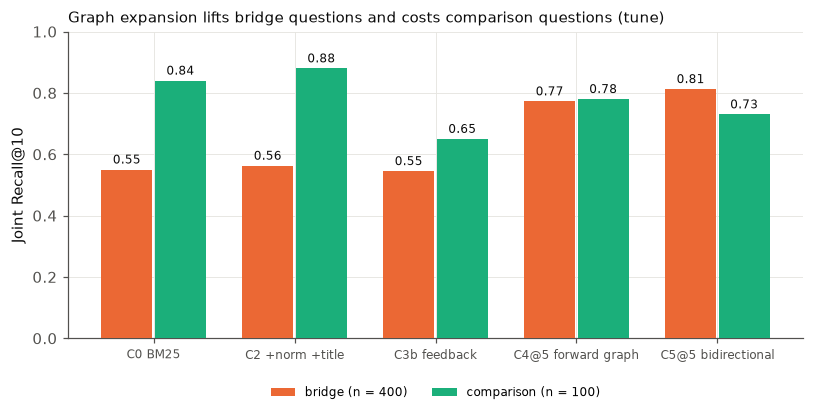

In [8]:
show = ["C0", "C2", "C3b", "C4@5", "C5@5"]
labels = {"C0": "C0 BM25", "C2": "C2 +norm +title", "C3b": "C3b feedback", "C4@5": "C4@5 forward graph", "C5@5": "C5@5 bidirectional"}
fig, ax = plt.subplots(figsize=(7.5, 3.9))
x = np.arange(len(show))
for i, (typ, color) in enumerate([("bridge", ORANGE), ("comparison", AQUA)]):
    vals = [np.mean([jr10[c][q] for q in rows if qd[q].type == typ]) for c in show]
    bars = ax.bar(x + (i - 0.5) * 0.38, vals, 0.36, color=color, zorder=3,
                  label=f"{typ} (n = {sum(qd[q].type == typ for q in rows)})")
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=2, fontsize=8, color=INK)
ax.set_xticks(x, [labels[c] for c in show], fontsize=8)
ax.set_ylim(0, 1)
ax.set_ylabel("Joint Recall@10")
ax.set_title("Graph expansion lifts bridge questions and costs comparison questions (tune)", fontsize=10, loc="left", color=INK)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

## 7. Phase 2a summary

**Classic champion: C5@5**, bidirectional title-mention expansion seeded from BM25's top
5. It raises overall Joint Recall@10 on `tune` from 0.608 to 0.796 (+0.188, 95% CI
[+0.144, +0.234]), about six times the 0.03 MPI.

Which classic mechanisms helped:

| Mechanism | Effect on overall Joint Recall@10 (`tune`) | Reading |
|---|---|---|
| Lexical normalization (C1) | +0.000 | Changes many rankings, but never whether both gold paragraphs are in the top 10 |
| Title repetition (C2) | +0.018 [+0.002, +0.034] | Small; inside the 0.02 plateau, so not adopted |
| Feedback (C3a / C3b) | −0.078 / −0.042 | Harmful: query drift towards the related entities of the first-round documents |
| Forward links (C4@5) | +0.166 | Second-hop Recall@10 0.62 → 0.86; forward edges exist for 82% of bridge questions |
| Adding backward links (C5@5 vs C4@5) | +0.040 on bridge | Recovers first hops that BM25 missed when it found the second (17 of 27) |

- **The trade-off.** Bridge Joint Recall@10 rises from 0.55 to 0.81, while comparison
  falls from 0.84 to 0.73. The reserved slots displace comparison questions' second
  entity. The selection metric is overall, so that trade-off is part of the result.
- **Described first hops remain the weak spot.** First-hop Recall@10 under C5@5 is 0.95
  when the question names the title and 0.86 when it only describes it (H2a-6: gap
  +0.088, short of the predicted 0.10 but above zero). This is the case Phase 2b's dense
  retriever is meant to address.
- **Cost stays negligible:** a 21-second graph build, and about 1 ms per query.

---

# Phase 2b — dense and hybrid retrieval

The classic champion C = C5@5 is the incumbent. There is one dense bi-encoder,
**TAS-B** (`msmarco-distilbert-base-tas-b`, pinned revision; CLS pooling, dot product, no
normalization; exact search), and one cross-encoder (`ms-marco-MiniLM-L6-v2`). Conclusions
are about TAS-B, not dense retrieval in general. Candidates, in preference order:

- **D0:** C5@5.
- **D1:** TAS-B alone.
- **D2:** RRF(C5@5, TAS-B).
- **D3:** the frozen graph operator G\* = C5@5 applied to H = RRF(BM25, TAS-B), with B's
  lexical scores for backward candidates.
- **D4:** the cross-encoder reranking D2's top 50.

## 8. Selection (`tune`, n = 500)

In [9]:
rows_b = {r["qid"]: r for r in read_jsonl("results/tune/phase2b_rankings.jsonl")}
sel_b = json.load(open("results/tune/phase2b_selection.json"))
DCONF = ["D0", "D1", "D2", "D3", "D4"]
jrb = {c: {q: metrics.joint_recall(rows_b[q]["rankings"][c][:10], gold[q]) for q in rows_b} for c in DCONF}
assert all(rows_b[q]["rankings"]["D0"] == rows[q]["rankings"]["C5@5"] for q in rows)   # D0 is C5@5 unchanged
tb = []
for c in DCONF:
    d = metrics.paired_bootstrap(jrb[c], jrb["D0"]) if c != "D0" else None
    tb.append({"config": c, "Joint Recall@10": np.mean(list(jrb[c].values())),
               "bridge": np.mean([jrb[c][q] for q in rows_b if qd[q].type == "bridge"]),
               "comparison": np.mean([jrb[c][q] for q in rows_b if qd[q].type == "comparison"]),
               "vs D0": "" if d is None else f"{d['delta']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]",
               "hop-1 R@10": np.mean([hop_id[q.qid][0] in rows_b[q.qid]["rankings"][c][:10] for q in bridge]),
               "hop-2 R@10": np.mean([hop_id[q.qid][1] in rows_b[q.qid]["rankings"][c][:10] for q in bridge]),
               "p50 ms": 1000 * np.median([rows_b[q]["latency_s"][c] for q in rows_b])})
display(pd.DataFrame(tb).set_index("config").round(3))
print(f"plateau {sel_b['plateau']} -> R = {sel_b['R']}; vs C0 (Phase 1 BM25): "
      f"{np.mean(list(jrb['D3'].values())) - np.mean(list(jr10['C0'].values())):+.3f}")

,Joint Recall@10,bridge,comparison,vs D0,hop-1 R@10,hop-2 R@10,p50 ms
config,,,,,,,
D0,0.796,0.812,0.73,,0.916,0.855,1.198
D1,0.568,0.478,0.93,"-0.228 [-0.280, -0.176]",0.923,0.533,35.115
D2,0.686,0.620,0.95,"-0.110 [-0.156, -0.064]",0.939,0.663,36.404
D3,0.826,0.818,0.86,"+0.030 [+0.004, +0.056]",0.939,0.855,36.433
D4,0.752,0.692,0.99,"-0.044 [-0.092, +0.002]",0.944,0.742,268.701


plateau ['D3'] -> R = D3; vs C0 (Phase 1 BM25): +0.218


## 9. The preregistered Phase 2b hypotheses

Exploratory, on `tune`. Differences are paired bootstrap estimates unless stated
otherwise. A threshold prediction "holds" only when the whole 95% interval clears the
threshold, as in Phase 2a.

In [10]:
unnamed_b = [q for q in bridge if not named[q.qid]]
h1 = metrics.paired_bootstrap({q.qid: float(hop_id[q.qid][0] in rows_b[q.qid]["rankings"]["D1"][:10]) for q in unnamed_b},
                              {q.qid: float(hop_id[q.qid][0] in rows_b[q.qid]["rankings"]["D0"][:10]) for q in unnamed_b})
m_all = {c: np.mean(list(jrb[c].values())) for c in DCONF}
bj_b = {c: {q: jrb[c][q] for q in rows_b if qd[q].type == "bridge"} for c in DCONF}
h3 = metrics.paired_bootstrap(bj_b["D3"], bj_b["D0"])
r3 = {c: {q: metrics.recall(rows_b[q]["rankings"][c][:3], gold[q]) for q in rows_b} for c in ("D2", "D4")}
h4a = metrics.paired_bootstrap(r3["D4"], r3["D2"])
h4b = metrics.paired_bootstrap({q.qid: float(hop_id[q.qid][1] in rows_b[q.qid]["rankings"]["D4"][:10]) for q in bridge},
                               {q.qid: float(hop_id[q.qid][1] in rows_b[q.qid]["rankings"]["D2"][:10]) for q in bridge})
best_d = max(DCONF[1:], key=lambda c: m_all[c])
h5 = metrics.paired_bootstrap(jrb[best_d], jrb["D0"])
hyp_b = pd.DataFrame([
    ("H2b-1", "D1 - C, first-hop R@10 on unnamed first hops >= +0.05", f"{fmt(h1)} (n = {len(unnamed_b)})",
     "holds" if h1["ci_low"] >= 0.05 else ("not shown" if h1["ci_high"] >= 0.05 else "contradicted")),
    ("H2b-2", "D2 above both C and D1, overall JR@10", f"D2 {m_all['D2']:.3f} vs C {m_all['D0']:.3f}, D1 {m_all['D1']:.3f}",
     "holds" if m_all["D2"] > max(m_all["D0"], m_all["D1"]) else "contradicted"),
    ("H2b-3", "G*(H) - G*(B), bridge JR@10 > 0", fmt(h3), "holds" if h3["ci_low"] > 0 else "not shown"),
    ("H2b-4", "D4 - D2: overall Recall@3 > 0", fmt(h4a), "holds" if h4a["ci_low"] > 0 else "not shown"),
    ("H2b-4", "D4 - D2: bridge hop-2 R@10 < 0", fmt(h4b),
     "holds" if h4b["ci_high"] < 0 else ("contradicted" if h4b["ci_low"] > 0 else "not shown")),
    ("H2b-5", f"best of D1-D4 ({best_d}) - C, overall JR@10 >= +0.03", fmt(h5),
     "holds" if h5["ci_low"] >= 0.03 else "not shown"),
], columns=["id", "prediction", "estimate [95% CI]", "result"]).set_index("id")
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(hyp_b)

,prediction,estimate [95% CI],result
id,,,
H2b-1,"D1 - C, first-hop R@10 on unnamed first hops >= +0.05","-0.067 [-0.134, +0.000] (n = 134)",contradicted
H2b-2,"D2 above both C and D1, overall JR@10","D2 0.686 vs C 0.796, D1 0.568",contradicted
H2b-3,"G*(H) - G*(B), bridge JR@10 > 0","+0.005 [-0.022, +0.030]",not shown
H2b-4,D4 - D2: overall Recall@3 > 0,"+0.061 [+0.039, +0.083]",holds
H2b-4,D4 - D2: bridge hop-2 R@10 < 0,"+0.079 [+0.043, +0.115]",contradicted
H2b-5,"best of D1-D4 (D3) - C, overall JR@10 >= +0.03","+0.030 [+0.004, +0.056]",not shown


## 10. Overlap and the source of D3's gain

- **Overlap:** gold paragraphs in the top 10 of the classic champion only, TAS-B only,
  both, or neither.
- **Dense seeds:** documents in H's top 5 (the seeds of D3) that are not in BM25's top 5.
- **Graph recovery:** second hops that D3 reaches through a link from such a seed.
- **Where the gain comes from:** D3 against D0, split by question type.

In [11]:
ov = {"classic only": 0, "TAS-B only": 0, "both": 0, "neither": 0}
for q in rows_b:
    c10, d10 = set(rows_b[q]["rankings"]["D0"][:10]), set(rows_b[q]["rankings"]["D1"][:10])
    for gd in gold[q]:
        ov["both" if gd in c10 and gd in d10 else "classic only" if gd in c10 else "TAS-B only" if gd in d10 else "neither"] += 1
print(f"gold paragraphs (n = {sum(ov.values())}) in the top 10 of C5@5 / TAS-B:", ov)

new_seeds = {q: [d for d in rows_b[q]["rankings"]["H"][:5] if d not in rows_b[q]["rankings"]["B"][:5]] for q in rows_b}
print(f"dense seeds per query (H top 5 not in BM25 top 5): mean {np.mean([len(v) for v in new_seeds.values()]):.2f}; "
      f"gold among them: {sum(len(set(v) & set(gold[q])) for q, v in new_seeds.items())}")
recovered = [q.qid for q in bridge if hop_id[q.qid][1] in [a["doc"] for a in rows_b[q.qid]["added"]["D3"]]
             and hop_id[q.qid][1] not in rows_b[q.qid]["rankings"]["D0"][:10]]
print(f"bridge second hops reached by D3's graph step but not by D0: {len(recovered)}")
lost = [q.qid for q in bridge if hop_id[q.qid][1] in rows_b[q.qid]["rankings"]["D0"][:10]
        and hop_id[q.qid][1] not in rows_b[q.qid]["rankings"]["D3"][:10]]
print(f"bridge second hops in D0's top 10 but not D3's: {len(lost)}")

for typ in ("bridge", "comparison"):
    qq = [q for q in rows_b if qd[q].type == typ]
    gain = sum(jrb["D3"][q] > jrb["D0"][q] for q in qq); loss = sum(jrb["D3"][q] < jrb["D0"][q] for q in qq)
    print(f"{typ:10s} (n = {len(qq)}): D3 gains Joint Recall@10 on {gain}, loses on {loss}; net {gain - loss:+d}")
print(f"\ncost: embedding {sel_b['embedding']['encode_s'] / 60:.1f} min on GPU, {sel_b['embedding']['bytes'] / 1e6:.0f} MB, "
      f"peak GPU {sel_b['embedding']['peak_gpu_bytes'] / 1e9:.2f} GB; fingerprint {sel_b['embedding']['fingerprint'][:16]}; "
      f"cross-encoder on CPU p50 {sel_b['rerank_cpu_latency_s']['p50_s']:.2f} s/query, "
      f"on GPU p50 {1000 * np.median([rows_b[q]['latency_s']['rerank_gpu'] for q in rows_b]):.0f} ms/query")

gold paragraphs (n = 1000) in the top 10 of C5@5 / TAS-B: {'classic only': 167, 'TAS-B only': 64, 'both': 712, 'neither': 57}
dense seeds per query (H top 5 not in BM25 top 5): mean 1.90; gold among them: 77
bridge second hops reached by D3's graph step but not by D0: 6
bridge second hops in D0's top 10 but not D3's: 11
bridge     (n = 400): D3 gains Joint Recall@10 on 15, loses on 13; net +2
comparison (n = 100): D3 gains Joint Recall@10 on 14, loses on 1; net +13

cost: embedding 10.7 min on GPU, 205 MB, peak GPU 1.50 GB; fingerprint 5411b3a2ec46d234; cross-encoder on CPU p50 1.09 s/query, on GPU p50 230 ms/query


## 11. Phase 2b summary

**Overall retriever: R = D3.** It is the frozen graph operator applied to seeds from
RRF(BM25, TAS-B), selected as the only plateau member.

- Joint Recall@10 on `tune` is **0.826**: +0.030 [+0.004, +0.056] over the classic
  champion, and +0.218 over Phase 1's BM25.
- The gain is above zero but not demonstrably at the 0.03 MPI (H2b-5 not shown).

What TAS-B contributes, and what it doesn't:

| Mechanism | Evidence (`tune`) |
|---|---|
| **Semantic retrieval alone** (D1) | Strong on comparison (0.93) and first hops (0.92), weak on hidden second hops (0.53). Overall 0.568, below BM25. It does **not** beat the graph champion on described first hops (H2b-1 contradicted) |
| **Fusion with the graph champion** (D2) | Hurts: 0.686. Averaging ranks dilutes the graph's added paragraphs (second-hop recall 0.86 → 0.66) (H2b-2 contradicted) |
| **Dense seeds for the graph** (D3) | Best overall. Gains are almost all on **comparison** questions (net +13 of 100) that the classic graph had hurt; bridge is unchanged (+0.005, H2b-3 not shown) |
| **Cross-encoder reranking** (D4) | Improves D2 on Recall@3 (+0.061) and, contrary to the preregistered worry, on second hops (+0.079). Comparison reaches 0.99. Still below D0 and D3 overall (0.752), at about 230 ms per query on the GPU and 1.1 s on the CPU |

The complementarity is the main result. **Link-following reaches hidden second hops;
semantic retrieval finds both named entities of comparison questions.** Combining them at
the seed stage keeps both strengths, while combining them at the ranking stage (RRF of
the final lists) loses the graph's contribution.

The costs of R over C5@5: a 10.7-minute one-off GPU encoding, a 205 MB matrix, and about
35 ms per query for the CPU question encoding.

## 12. End to end on `dev`: does the better retriever give better answers?

R = D3 was frozen (commit `0af5786`) and run **once** on the 100 `dev` questions, with K = 10
and the unchanged answer interface (`answer_v2`, schema v2, `render_v1`, the system
prompt). The Phase 1 BM25 K = 10 run was replayed from the LLM cache only, under the same
code. Both manifests pass the final-comparison check: same clean commit, identical
invariants, and the shared answer interface asserted equal. All differences are paired
bootstrap estimates over the same 100 questions, and they are exploratory.

In [12]:
import manifest
import scoring

dev = data.load_split("dev")
qdev = {q.qid: q for q in dev}
e2e = {n: read_jsonl(f"results/dev/{n}.jsonl") for n in ("bm25_k10_replay", "d3_k10")}
mans = {n: json.load(open(f"results/dev/{n}.jsonl.manifest.json")) for n in e2e}
diff_cfg = manifest.check_comparable(mans["bm25_k10_replay"], mans["d3_k10"], final=True,
                                     shared=["answer_prompt_hash", "schema_hash", "system_prompt_hash",
                                             "renderer_hash", "answer_validator_hash"])
print("comparable (final rule); allowed configuration differences:", sorted(diff_cfg))
print("new generations: BM25 replay", sum(not r["llm"]["cached"] for r in e2e["bm25_k10_replay"]),
      "| D3 (all from its single original run)", sum(not r["llm"]["cached"] for r in e2e["d3_k10"]))
sc = {n: {r["qid"]: scoring.score(qdev[r["qid"]], r) for r in rs} for n, rs in e2e.items()}
NAMES = {"f1": "answer F1", "em": "EM", "ctx_joint_recall": "context Joint Recall", "sp_strict_f1": "evidence F1 (strict)",
         "sp_official_f1": "evidence F1 (official-compatible)", "joint_official_f1": "joint F1 (official)",
         "supported": "supported rate", "all_valid_citations": "all citations valid",
         "incomplete_gold_evidence": "incomplete-gold-evidence proxy"}
out = []
for m, label in NAMES.items():
    a = {q: s[m] for q, s in sc["d3_k10"].items()}
    b = {q: s[m] for q, s in sc["bm25_k10_replay"].items()}
    r = metrics.paired_bootstrap(a, b)
    out.append({"metric": label, "BM25 K=10": np.mean(list(b.values())), "D3 K=10": np.mean(list(a.values())),
                "D3 - BM25 [95% CI]": f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"})
display(pd.DataFrame(out).set_index("metric").round(3))
for typ in ("bridge", "comparison"):
    a = {q: s["f1"] for q, s in sc["d3_k10"].items() if s["type"] == typ}
    b = {q: s["f1"] for q, s in sc["bm25_k10_replay"].items() if s["type"] == typ}
    r = metrics.paired_bootstrap(a, b)
    print(f"answer F1 {typ:10s} (n = {len(a)}): BM25 {np.mean(list(b.values())):.3f}  D3 {np.mean(list(a.values())):.3f}  "
          f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]")
for n, rs in e2e.items():
    print(f"{n:16s} calls 1 retrieval + 1 LLM; retrieval p50 {1000 * np.median([r['retrieval_s'] for r in rs]):.1f} ms; "
          f"prompt tokens {np.mean([r['llm']['prompt_tokens'] for r in rs]):.0f}; output tokens {np.mean([r['llm']['output_tokens'] for r in rs]):.0f}; "
          f"LLM p50 {np.median([r['llm']['wall_s'] for r in rs]):.1f} s")

comparable (final rule); allowed configuration differences: ['replay_of', 'retriever', 'system']
new generations: BM25 replay 0 | D3 (all from its single original run) 0


,BM25 K=10,D3 K=10,D3 - BM25 [95% CI]
metric,,,
answer F1,0.525,0.629,"+0.104 [+0.020, +0.189]"
EM,0.410,0.470,"+0.060 [-0.020, +0.140]"
context Joint Recall,0.620,0.840,"+0.220 [+0.120, +0.320]"
evidence F1 (strict),0.327,0.453,"+0.126 [+0.042, +0.209]"
evidence F1 (official-compatible),0.327,0.453,"+0.126 [+0.042, +0.209]"
joint F1 (official),0.245,0.335,"+0.090 [+0.016, +0.165]"
supported rate,0.750,0.870,"+0.120 [+0.030, +0.210]"
all citations valid,0.820,0.920,"+0.100 [+0.010, +0.190]"
incomplete-gold-evidence proxy,0.710,0.640,"-0.070 [-0.170, +0.040]"


answer F1 bridge     (n = 80): BM25 0.486  D3 0.622  +0.136 [+0.034, +0.238]
answer F1 comparison (n = 20): BM25 0.680  D3 0.659  -0.021 [-0.064, +0.000]
bm25_k10_replay  calls 1 retrieval + 1 LLM; retrieval p50 0.6 ms; prompt tokens 1716; output tokens 96; LLM p50 20.6 s
d3_k10           calls 1 retrieval + 1 LLM; retrieval p50 34.0 ms; prompt tokens 1752; output tokens 96; LLM p50 23.3 s


**The better retriever gives better answers.**

- **Answer F1** rises from 0.525 to 0.629 (+0.104 [+0.020, +0.189]).
- **Both gold paragraphs** reach the context for 84% of questions instead of 62%.
- **Evidence, grounding and support** improve together: strict evidence F1, the joint
  metric, the supported rate and citation validity.
- **EM** moves in the same direction, but its interval includes zero.
- **By type:** the gain is on bridge questions (+0.136). Comparison questions (n = 20)
  are flat or slightly lower.
- **Cost:** retrieval takes 34 ms instead of 0.6 ms, negligible next to one LLM call.

The D3 records carry no new generations. They were re-produced from the cache of the
single original D3 run, after the replay-manifest fix, and are identical to it. LLM wall
time is the original generation's (23.3 s median, against 20.6 s for BM25 at nearly the
same prompt size); the difference is observed, not explained.

---

## 13. Post-hoc interaction check: X1 = cross-encoder reranking of D3

**Post hoc** (`PREREGISTRATION.md` P1, recorded after the Phase 2b `tune` results and
before X1 was run). D4's unexpectedly positive result suggested an untested composition.

- **Definition:** X1 reranks exactly D3's first 50 with D4's settings.
- **Carry rule:** carry X1 forward only if X1 − D3 > 0.02 in overall Joint Recall@10.
- **Status:** X1 is not a Phase 2b candidate, and the selection table and hypothesis
  outcomes above are unchanged. **D3 remains the preregistered winner R.**

In [13]:
x1_rows = {r["qid"]: r["ranking"] for r in read_jsonl("results/tune/posthoc_x1_rankings.jsonl")}
x1_sum = json.load(open("results/tune/posthoc_x1_summary.json"))
x1_man = json.load(open("results/tune/posthoc_x1_rankings.jsonl.manifest.json"))
import run_eval
assert x1_man["system_config"]["posthoc"] is True
assert x1_man["system_config"]["d3_rankings_fingerprint"] == run_eval.rankings_fingerprint({q: rows_b[q]["rankings"]["D3"] for q in rows_b})
R3 = {"D3": {q: rows_b[q]["rankings"]["D3"] for q in rows_b}, "X1": x1_rows, "D4": {q: rows_b[q]["rankings"]["D4"] for q in rows_b}}
jx = {s: {q: metrics.joint_recall(R3[s][q][:10], gold[q]) for q in rows_b} for s in R3}
rx3 = {s: {q: metrics.recall(R3[s][q][:3], gold[q]) for q in rows_b} for s in R3}
hopx = {s: {w: {q.qid: float(hop_id[q.qid][w] in R3[s][q.qid][:10]) for q in bridge} for w in (0, 1)} for s in R3}
tab = []
for s in ("D3", "X1", "D4"):
    tab.append({"system": s + (" (R)" if s == "D3" else " (post hoc)" if s == "X1" else ""),
                "JR@10": np.mean(list(jx[s].values())),
                "bridge": np.mean([jx[s][q] for q in rows_b if qd[q].type == "bridge"]),
                "comparison": np.mean([jx[s][q] for q in rows_b if qd[q].type == "comparison"]),
                "Recall@3": np.mean(list(rx3[s].values())),
                "hop-1 R@10": np.mean(list(hopx[s][0].values())), "hop-2 R@10": np.mean(list(hopx[s][1].values()))})
display(pd.DataFrame(tab).set_index("system").round(3))
for label, a, b in (("JR@10", jx["X1"], jx["D3"]), ("Recall@3", rx3["X1"], rx3["D3"]), ("hop-2 R@10", hopx["X1"][1], hopx["D3"][1]),
                    ("hop-1 R@10", hopx["X1"][0], hopx["D3"][0])):
    print(f"X1 - D3 {label:10s} {fmt(metrics.paired_bootstrap(a, b))}")
for typ in ("bridge", "comparison"):
    print(f"X1 - D3 JR@10 {typ:10s} {fmt(metrics.paired_bootstrap({q: jx['X1'][q] for q in rows_b if qd[q].type == typ}, {q: jx['D3'][q] for q in rows_b if qd[q].type == typ}))}")
print(f"X1 - D4 JR@10 {fmt(metrics.paired_bootstrap(jx['X1'], jx['D4']))}")
same_order = sum(R3["X1"][q][:10] == R3["D4"][q][:10] for q in rows_b)
shared = pd.Series([len(set(R3["X1"][q][:10]) & set(R3["D4"][q][:10])) for q in rows_b]).value_counts().sort_index(ascending=False)
print(f"X1 vs D4 top 10: identical ordered lists {same_order}/500; shared documents per question: {shared.to_dict()}")
moves = {"promoted": 0, "unchanged": 0, "demoted, kept": 0, "removed from top 10": 0}
for q in rows_b:
    for a in rows_b[q]["added"]["D3"]:
        if a["doc"] not in gold[q]:
            continue
        p3 = R3["D3"][q].index(a["doc"])
        px = R3["X1"][q][:10].index(a["doc"]) if a["doc"] in R3["X1"][q][:10] else None
        moves["removed from top 10" if px is None else "promoted" if px < p3 else "demoted, kept" if px > p3 else "unchanged"] += 1
print(f"graph-added gold paragraphs in D3's top 10: {sum(moves.values())} -> {moves} "
      f"({moves['removed from top 10'] / sum(moves.values()):.0%} removed)")
print(f"carry gate: X1 - D3 = {x1_sum['difference']:+.3f} -> carried: {x1_sum['carry']}; rerank latency p50: "
      f"GPU {1000 * x1_sum['rerank_gpu_latency_s']['p50_s']:.0f} ms, CPU {x1_sum['rerank_cpu_latency_s']['p50_s']:.2f} s")

,JR@10,bridge,comparison,Recall@3,hop-1 R@10,hop-2 R@10
system,,,,,,
D3 (R),0.826,0.818,0.86,0.675,0.939,0.855
X1 (post hoc),0.750,0.692,0.98,0.753,0.944,0.742
D4,0.752,0.692,0.99,0.754,0.944,0.742


X1 - D3 JR@10      -0.076 [-0.120, -0.034]


X1 - D3 Recall@3   +0.078 [+0.057, +0.099]
X1 - D3 hop-2 R@10 -0.112 [-0.161, -0.064]
X1 - D3 hop-1 R@10 +0.005 [-0.020, +0.031]


X1 - D3 JR@10 bridge     -0.125 [-0.177, -0.075]
X1 - D3 JR@10 comparison +0.120 [+0.060, +0.190]
X1 - D4 JR@10 -0.002 [-0.012, +0.006]
X1 vs D4 top 10: identical ordered lists 440/500; shared documents per question: {10: 440, 9: 57, 8: 3}
graph-added gold paragraphs in D3's top 10: 157 -> {'promoted': 54, 'unchanged': 4, 'demoted, kept': 17, 'removed from top 10': 82} (52% removed)
carry gate: X1 - D3 = -0.076 -> carried: False; rerank latency p50: GPU 226 ms, CPU 1.05 s


**X1 fails the carry gate** (−0.076 [−0.120, −0.034]), so D3 remains the only retriever
carried forward.

- **What X1 does:** it raises Recall@3 (+0.078) and comparison Joint Recall (0.86 → 0.98).
  But it lowers bridge Joint Recall (−0.125), because it drops second hops (−0.112).
- **Removed evidence:** of the 157 gold paragraphs that D3's graph step placed in the top
  10, reranking removes 82 (52%).
- **The cross-encoder decides the final list:** X1 and D4 have identical ordered top 10s
  for 440 of 500 questions, share 9 of 10 documents for 57 and 8 of 10 for 3. So the
  reranker largely determines the result, whether D2 or D3 supplies the candidates.
- **Rereading H2b-4:** reranking looked harmless there only because D2's fusion had
  already diluted the graph's additions.

**The ordering of individually reasonable components matters:**

```text
question-only fusion  → graph expansion           D3: keeps hidden-hop evidence
graph expansion       → question-only reranking   X1: often removes hidden-hop evidence
```

In this experiment, question–paragraph reranking improved direct relevance but removed
52% of the graph-added gold evidence, undoing much of the multi-hop gain. The result
applies to this pointwise MS MARCO cross-encoder and this pipeline order. A multi-hop-aware
reranker, protected graph slots, or reranking *before* graph expansion could behave
differently; none of those was tested.